<a href="https://colab.research.google.com/github/dilarabcde/GreenPipeline/blob/main/01_ACRIMA_Data_Analysis_ipynb_adl%C4%B1_not_defterinin_kopyas%C4%B1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import drive
from pathlib import Path

# Google Drive'ı bağla
drive.mount('/content/drive')

# Proje ana klasörü
ROOT = Path('/content/drive/MyDrive/ACRIMA_Glaucoma_Project')

folders = [
    "data/raw",
    "data/splits",
    "notebooks",
    "src",
    "models",
    "results",
    "figures",
    "reports"
]

for folder in folders:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

print("Proje klasörleri oluşturuldu!")
print(ROOT)


Mounted at /content/drive
Proje klasörleri oluşturuldu!
/content/drive/MyDrive/ACRIMA_Glaucoma_Project


In [ ]:

from pathlib import Path
import zipfile

zip_path = ROOT / "Database.zip"
extract_path = Path("/content/acrima_data")

# ZIP dosyasını kontrol et
print("ZIP mevcut mu?", zip_path.exists())

# Colab'ın geçici diskine çıkar
extract_path.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("ZIP başarıyla açıldı!")

# Çıkarılan klasörleri göster
for item in extract_path.iterdir():
    print(item.name)


ZIP mevcut mu? True
ZIP başarıyla açıldı!
__MACOSX
Database


In [ ]:

from pathlib import Path

# Görüntülerin bulunduğu klasör
image_dir = extract_path / "Database" / "Images"

# JPG görüntülerini listele
image_files = sorted(image_dir.glob("*.jpg"))

print("Toplam görüntü sayısı:", len(image_files))

print("\nİlk 10 görüntü:")
for file in image_files[:10]:
    print(file.name)

print("\nSon 5 görüntü:")
for file in image_files[-5:]:
    print(file.name)


Toplam görüntü sayısı: 703

İlk 10 görüntü:
Im001_ACRIMA.jpg
Im002_ACRIMA.jpg
Im003_ACRIMA.jpg
Im004_ACRIMA.jpg
Im005_ACRIMA.jpg
Im006_ACRIMA.jpg
Im007_ACRIMA.jpg
Im008_ACRIMA.jpg
Im009_ACRIMA.jpg
Im010_ACRIMA.jpg

Son 5 görüntü:
Im699_g_ACRIMA.jpg
Im700_g_ACRIMA.jpg
Im701_g_ACRIMA.jpg
Im704_g_ACRIMA.jpg
Im705_g_ACRIMA.jpg


In [ ]:

# Klasörde bulunan görüntü numaraları
import re

numbers = set()

for file in image_files:
    match = re.match(r"Im(\d+)", file.name)
    if match:
        numbers.add(int(match.group(1)))

# 1 ile 705 arasındaki eksik numaralar
missing = sorted(set(range(1, 706)) - numbers)

print("Eksik görüntü numaraları:", missing)

# JPG dışında başka görüntüler var mı?
other_files = [
    p.name for p in image_dir.iterdir()
    if p.is_file() and p.suffix.lower() != ".jpg"
]

print("JPG dışındaki dosyalar:", other_files)

# Glokom ve normal görüntü sayılarını kontrol et
glaucoma = [
    p for p in image_files
    if "_g_" in p.name.lower()
]

normal = [
    p for p in image_files
    if "_g_" not in p.name.lower()
]

print("Glokomlu:", len(glaucoma))
print("Normal:", len(normal))
print("Toplam:", len(glaucoma) + len(normal))


Eksik görüntü numaraları: [702, 703]
JPG dışındaki dosyalar: []
Glokomlu: 394
Normal: 309
Toplam: 703


In [ ]:

import zipfile

with zipfile.ZipFile(zip_path, "r") as z:
    names = z.namelist()

    for num in [702, 703]:
        matches = [
            name for name in names
            if f"Im{num}_" in name
        ]
        print(f"Im{num}:", matches if matches else "ZIP içinde yok")

    print("ZIP içindeki toplam dosya:", len(names))


Im702: ['Database/Images/Im702_g_ACRIMA.JPG', '__MACOSX/Database/Images/._Im702_g_ACRIMA.JPG']
Im703: ['Database/Images/Im703_g_ACRIMA.JPG', '__MACOSX/Database/Images/._Im703_g_ACRIMA.JPG']
ZIP içindeki toplam dosya: 1418


In [ ]:

# Büyük ve küçük harfli JPG dosyalarını birlikte al
image_files = sorted(
    p for p in image_dir.iterdir()
    if p.is_file() and p.suffix.lower() == ".jpg"
)

# Sınıfları ayır
glaucoma = [
    p for p in image_files
    if "_g_" in p.name.lower()
]

normal = [
    p for p in image_files
    if "_g_" not in p.name.lower()
]

print("Toplam görüntü:", len(image_files))
print("Glokomlu:", len(glaucoma))
print("Normal:", len(normal))

assert len(image_files) == 705, "Görüntü sayısı beklenenden farklı!"
assert len(glaucoma) == 396, "Glokomlu sınıf sayısı farklı!"
assert len(normal) == 309, "Normal sınıf sayısı farklı!"

print("Veri seti sayım kontrolü başarılı!")


Toplam görüntü: 705
Glokomlu: 396
Normal: 309
Veri seti sayım kontrolü başarılı!


In [ ]:

from PIL import Image
import pandas as pd

data = []
bozuk_dosyalar = []

for dosya in image_files:
    try:
        with Image.open(dosya) as img:
            img.load()

            data.append({
                "dosya_adi": dosya.name,
                "sinif": "Glokom" if "_g_" in dosya.name.lower() else "Normal",
                "genislik": img.width,
                "yukseklik": img.height,
                "format": img.format
            })

    except Exception as e:
        bozuk_dosyalar.append((dosya.name, str(e)))

df = pd.DataFrame(data)

print("Okunabilen görüntü sayısı:", len(df))
print("Bozuk görüntü sayısı:", len(bozuk_dosyalar))

print("\nİlk 5 satır:")
print(df.head())

print("\nGörüntü boyutları:")
print(df[["genislik", "yukseklik"]].describe())

print("\nBozuk dosyalar:")
print(bozuk_dosyalar)


Okunabilen görüntü sayısı: 705
Bozuk görüntü sayısı: 0

İlk 5 satır:
          dosya_adi   sinif  genislik  yukseklik format
0  Im001_ACRIMA.jpg  Normal       349        349   JPEG
1  Im002_ACRIMA.jpg  Normal       277        277   JPEG
2  Im003_ACRIMA.jpg  Normal       409        409   JPEG
3  Im004_ACRIMA.jpg  Normal       406        406   JPEG
4  Im005_ACRIMA.jpg  Normal       316        316   JPEG

Görüntü boyutları:
          genislik    yukseklik
count   705.000000   705.000000
mean    529.719149   529.009929
std     243.509685   243.053518
min     178.000000   178.000000
25%     340.000000   340.000000
50%     424.000000   421.000000
75%     718.000000   712.000000
max    1420.000000  1420.000000

Bozuk dosyalar:
[]


Sınıf dağılımı:
sinif
Glokom    396
Normal    309
Name: count, dtype: int64


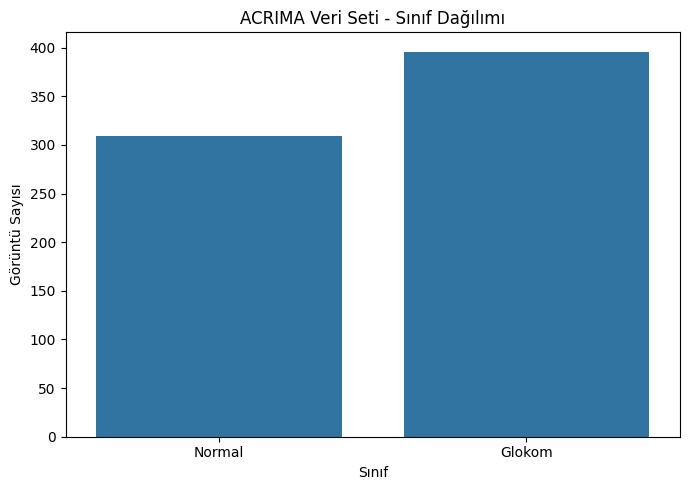

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Sınıf sayılarını hesapla
sinif_sayilari = df["sinif"].value_counts()

print("Sınıf dağılımı:")
print(sinif_sayilari)

# Grafik oluştur
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="sinif",
    order=["Normal", "Glokom"]
)

plt.title("ACRIMA Veri Seti - Sınıf Dağılımı")
plt.xlabel("Sınıf")
plt.ylabel("Görüntü Sayısı")

plt.tight_layout()
plt.show()


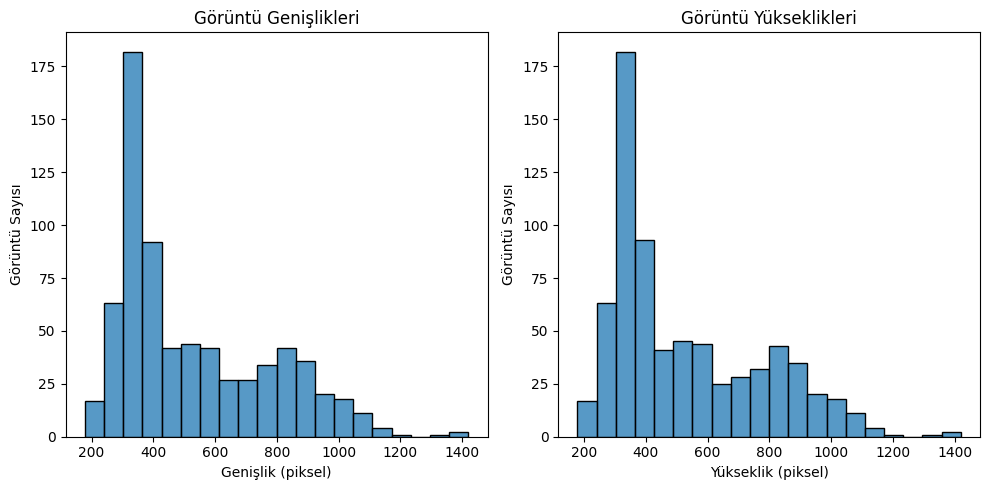

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

# Görüntü genişliklerinin dağılımı
plt.subplot(1, 2, 1)
sns.histplot(data=df, x="genislik", bins=20)
plt.title("Görüntü Genişlikleri")
plt.xlabel("Genişlik (piksel)")
plt.ylabel("Görüntü Sayısı")

# Görüntü yüksekliklerinin dağılımı
plt.subplot(1, 2, 2)
sns.histplot(data=df, x="yukseklik", bins=20)
plt.title("Görüntü Yükseklikleri")
plt.xlabel("Yükseklik (piksel)")
plt.ylabel("Görüntü Sayısı")

plt.tight_layout()
plt.show()


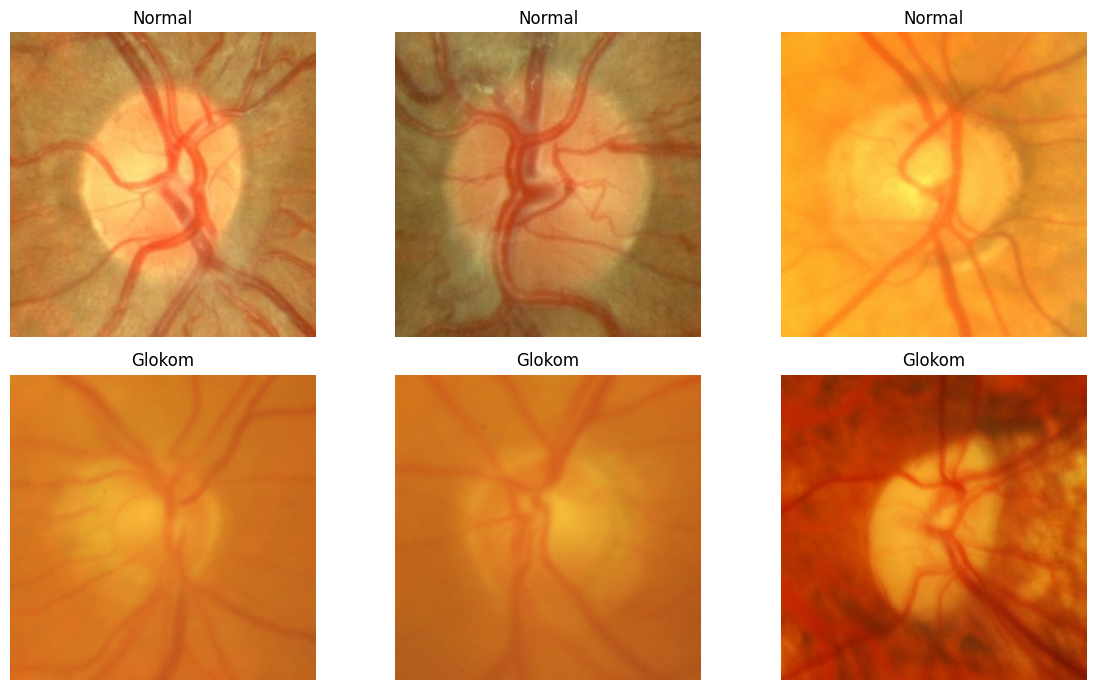

In [ ]:

import matplotlib.pyplot as plt
from PIL import Image

# Her sınıftan 3 görüntü seç
ornek_normal = normal[:3]
ornek_glokom = glaucoma[:3]

plt.figure(figsize=(12, 7))

# Normal görüntüler
for i, dosya in enumerate(ornek_normal):
    plt.subplot(2, 3, i + 1)

    with Image.open(dosya) as img:
        plt.imshow(img.convert("RGB"))

    plt.title("Normal")
    plt.axis("off")

# Glokomlu görüntüler
for i, dosya in enumerate(ornek_glokom):
    plt.subplot(2, 3, i + 4)

    with Image.open(dosya) as img:
        plt.imshow(img.convert("RGB"))

    plt.title("Glokom")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
!pip install ImageHash -q

In [ ]:

import imagehash
from PIL import Image
from itertools import combinations

# Her görüntünün pHash değerini hesapla
hash_degerleri = {}

for dosya in image_files:
    with Image.open(dosya) as img:
        hash_degerleri[dosya.name] = imagehash.phash(img)

# Benzer görüntü çiftlerini bul
benzer_goruntuler = []

for dosya1, dosya2 in combinations(image_files, 2):
    uzaklik = (
        hash_degerleri[dosya1.name] -
        hash_degerleri[dosya2.name]
    )

    if uzaklik <= 5:
        benzer_goruntuler.append(
            (dosya1.name, dosya2.name, uzaklik)
        )

print("Benzer görüntü çifti sayısı:", len(benzer_goruntuler))

print("\nİlk 10 benzer çift:")
for cift in benzer_goruntuler[:10]:
    print(cift)


Benzer görüntü çifti sayısı: 0

İlk 10 benzer çift:


In [ ]:
from pathlib import Path

readme_path = extract_path / "Database" / "Readme.txt"

with open(readme_path, "r", encoding="utf-8", errors="replace") as f:
    print(f.read())


################   ACRIMA Database    ################

ACRIMA database is composed by 705 fundus images (396 glaucomatous and 309 normal images). They were collected at the FISABIO Oftalmología Médica in Valencia, Spain, from glaucomatous and normal patients with their previous consent and in accordance with the ethical standards laid down in the 1964 Declaration of Helsinki. All images from ACRIMA database were annotated by glaucoma experts with several years of experience. They were cropped around the optic disc and renamed. 

The image name has the following structure: First, the name starts with the two letters "Im", followed by an image number composed by three digits (starting from 001 until 705), followed by the label (this label is "_g_" if the image is pathological and "_" if the image is normal). Finally, all image names have the database name, "ACRIMA", at the end of their names. For example, a name for a glaucomatous image is "Im686_g_ACRIMA" and "Im001_ACRIMA" for a norma

In [ ]:

from sklearn.model_selection import train_test_split
import pandas as pd

# Görüntü ve etiket bilgileri
X = df["dosya_adi"]
y = df["sinif"]

# Önce %70 eğitim, %30 geçici küme
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Geçici kümeyi eşit ikiye böl: %15 validation, %15 test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

print("\nEğitim sınıf dağılımı:")
print(y_train.value_counts())

print("\nDoğrulama sınıf dağılımı:")
print(y_val.value_counts())

print("\nTest sınıf dağılımı:")
print(y_test.value_counts())


Training: 493
Validation: 106
Test: 106

Eğitim sınıf dağılımı:
sinif
Glokom    277
Normal    216
Name: count, dtype: int64

Doğrulama sınıf dağılımı:
sinif
Glokom    60
Normal    46
Name: count, dtype: int64

Test sınıf dağılımı:
sinif
Glokom    59
Normal    47
Name: count, dtype: int64


In [ ]:

import pandas as pd

# Kayıt klasörü
split_dir = ROOT / "data" / "splits"
split_dir.mkdir(parents=True, exist_ok=True)

# Eğitim verilerini kaydet
train_df = pd.DataFrame({
    "dosya_adi": X_train.values,
    "sinif": y_train.values
})

# Doğrulama verilerini kaydet
val_df = pd.DataFrame({
    "dosya_adi": X_val.values,
    "sinif": y_val.values
})

# Test verilerini kaydet
test_df = pd.DataFrame({
    "dosya_adi": X_test.values,
    "sinif": y_test.values
})

train_df.to_csv(split_dir / "train.csv", index=False)
val_df.to_csv(split_dir / "val.csv", index=False)
test_df.to_csv(split_dir / "test.csv", index=False)

print("Veri bölmeleri kaydedildi!")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Kayıt konumu:", split_dir)


Veri bölmeleri kaydedildi!
Training: 493
Validation: 106
Test: 106
Kayıt konumu: /content/drive/MyDrive/ACRIMA_Glaucoma_Project/data/splits


In [ ]:

from skimage.feature import hog
from PIL import Image
import numpy as np

# Görüntüden HOG özelliklerini çıkar
def hog_ozellik(dosya_adi):

    yol = image_dir / dosya_adi

    with Image.open(yol) as img:
        img = img.convert("L")
        img = img.resize((128, 128))

        goruntu = np.array(img)

    ozellikler = hog(
        goruntu,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2)
    )

    return ozellikler

# Eğitim ve doğrulama özellikleri
X_train_hog = np.array([
    hog_ozellik(dosya)
    for dosya in train_df["dosya_adi"]
])

X_val_hog = np.array([
    hog_ozellik(dosya)
    for dosya in val_df["dosya_adi"]
])

print("Eğitim:", X_train_hog.shape)
print("Doğrulama:", X_val_hog.shape)


Eğitim: (493, 8100)
Doğrulama: (106, 8100)


In [ ]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# SVM modelini oluştur
model = SVC(kernel="linear")

# Modeli eğit
model.fit(X_train_hog, train_df["sinif"])

# Doğrulama verisiyle tahmin yap
y_pred = model.predict(X_val_hog)

# Sonuçları hesapla
accuracy = accuracy_score(val_df["sinif"], y_pred)

print("Validation Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(
    val_df["sinif"],
    y_pred,
    digits=4
))


Validation Accuracy: 0.8113207547169812

Classification Report:
              precision    recall  f1-score   support

      Glokom     0.8125    0.8667    0.8387        60
      Normal     0.8095    0.7391    0.7727        46

    accuracy                         0.8113       106
   macro avg     0.8110    0.8029    0.8057       106
weighted avg     0.8112    0.8113    0.8101       106



In [ ]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# SVM modelini oluştur
model = SVC(kernel="linear")

# Modeli eğit
model.fit(X_train_hog, train_df["sinif"])

# Doğrulama verisiyle tahmin yap
y_pred = model.predict(X_val_hog)

# Sonuçları hesapla
accuracy = accuracy_score(val_df["sinif"], y_pred)

print("Validation Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(
    val_df["sinif"],
    y_pred,
    digits=4
))


Validation Accuracy: 0.8113207547169812

Classification Report:
              precision    recall  f1-score   support

      Glokom     0.8125    0.8667    0.8387        60
      Normal     0.8095    0.7391    0.7727        46

    accuracy                         0.8113       106
   macro avg     0.8110    0.8029    0.8057       106
weighted avg     0.8112    0.8113    0.8101       106



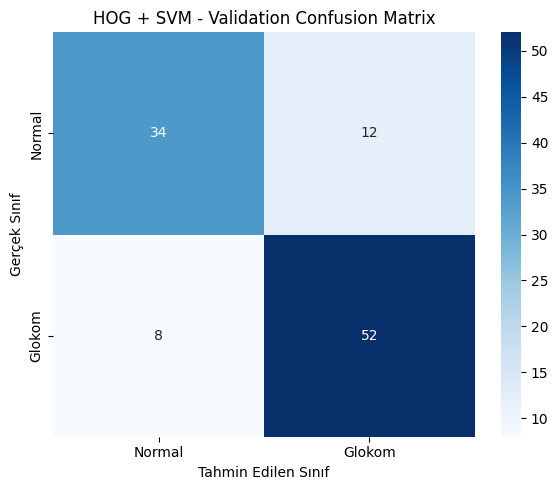

In [ ]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Sınıf sırasını belirle
siniflar = ["Normal", "Glokom"]

# Hata matrisini hesapla
cm = confusion_matrix(
    val_df["sinif"],
    y_pred,
    labels=siniflar
)

# Grafiği oluştur
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=siniflar,
    yticklabels=siniflar
)

plt.title("HOG + SVM - Validation Confusion Matrix")
plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")

plt.tight_layout()
plt.show()


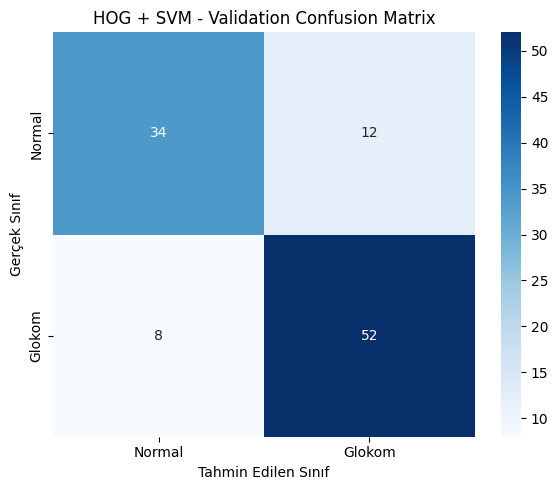

Sonuçlar kaydedildi!
     model veri_kumesi  accuracy  macro_f1  balanced_accuracy  seed
0  HOG_SVM  validation  0.811321  0.805718           0.802899    42


In [ ]:

from sklearn.metrics import f1_score, balanced_accuracy_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Sonuç klasörlerini oluştur
results_dir = ROOT / "results"
figures_dir = ROOT / "figures"

results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Performans değerlerini hesapla
accuracy = accuracy_score(val_df["sinif"], y_pred)
macro_f1 = f1_score(
    val_df["sinif"], y_pred, average="macro"
)
balanced_acc = balanced_accuracy_score(
    val_df["sinif"], y_pred
)

# Sonuçları tabloya dönüştür
sonuclar = pd.DataFrame([{
    "model": "HOG_SVM",
    "veri_kumesi": "validation",
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "balanced_accuracy": balanced_acc,
    "seed": 42
}])

# CSV olarak kaydet
sonuclar.to_csv(
    results_dir / "baseline_results.csv",
    index=False
)

# Confusion Matrix grafiğini kaydet
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Glokom"],
    yticklabels=["Normal", "Glokom"]
)

plt.title("HOG + SVM - Validation Confusion Matrix")
plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")

plt.tight_layout()

plt.savefig(
    figures_dir / "hog_svm_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Sonuçlar kaydedildi!")
print(sonuclar)
